# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Zahwa Ayu Ramadhani
- **Email:** zahwaayurmdhni@gmail.com
- **ID Dicoding:** zahwa_ayu_ramadh3put

## Menentukan Pertanyaan Bisnis

**Konteks:** Dataset ini berisi transaksi marketplace e-commerce Brasil (Olist) pada periode September 2016 – Oktober 2018.
Data pada tahun 2016 dan September–Oktober 2018 sangat sedikit (bulan tidak lengkap), sehingga **periode analisis dibatasi pada Januari 2017 – Agustus 2018 (20 bulan penuh)**
dan hanya mencakup pesanan berstatus `delivered` (pesanan yang benar-benar menghasilkan pendapatan).

Seluruh pertanyaan di bawah ini disusun dengan kerangka **SMART** (Specific, Measurable, Action-Oriented, Relevant, Time-bound):

- **Pertanyaan 1:** Kategori produk apa saja yang menjadi 10 kontributor *revenue* (total harga produk, di luar ongkir) terbesar dan 5 kontributor terkecil selama periode Januari 2017 – Agustus 2018, serta berapa persen kontribusi Top 5 kategori terhadap total *revenue*?
- **Pertanyaan 2:** Bagaimana tren jumlah pesanan dan total *revenue* bulanan (*Month-over-Month*) selama Januari 2017 – Agustus 2018, dan berapa persen pertumbuhan *revenue* periode Januari–Agustus 2018 dibandingkan Januari–Agustus 2017 (*Year-over-Year*)?
- **Pertanyaan 3:** Seberapa besar penurunan rata-rata skor ulasan (*review score*) pelanggan akibat keterlambatan pengiriman (dibanding perkiraan tanggal tiba) selama Januari 2017 – Agustus 2018, dan di negara bagian (*state*) mana tingkat keterlambatan tertinggi serta skor ulasan terendah?

**Analisis lanjutan** (tanpa algoritma *machine learning*) yang diterapkan untuk memperkuat hasil: **RFM Analysis** (+ *manual grouping*), **Geospatial Analysis**, dan **Binning** (pengelompokan keterlambatan pengiriman).

## Import Semua Packages/Library yang Digunakan

In [86]:
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patheffects as pe
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

# Warna konsisten: biru = sorotan utama, abu-abu = pembanding
HIGHLIGHT = '#1f77b4'
MUTED = '#c9ced6'
WARN = '#d62728'

## Data Wrangling

### Gathering Data

Pada tahap ini seluruh tabel dari E-Commerce Public Dataset dimuat ke dalam *DataFrame*. Tabel yang dimuat:

| Tabel | Isi |
|---|---|
| `orders` | status & timestamp setiap pesanan |
| `order_items` | item/produk di setiap pesanan (harga, ongkir) |
| `order_payments` | detail pembayaran |
| `order_reviews` | skor & komentar ulasan |
| `customers` | data pelanggan (kota, state, kode pos) |
| `sellers` | data penjual |
| `products` + `product_category_name_translation` | data produk & terjemahan nama kategori |
| `geolocation` | koordinat latitude/longitude berdasarkan kode pos |

#### Load df orders, order_items, order_payments, dan order_reviews

In [87]:
DATA_DIR = 'data/'

orders_df = pd.read_csv(DATA_DIR + 'orders_dataset.csv')
order_items_df = pd.read_csv(DATA_DIR + 'order_items_dataset.csv')
order_payments_df = pd.read_csv(DATA_DIR + 'order_payments_dataset.csv')
order_reviews_df = pd.read_csv(DATA_DIR + 'order_reviews_dataset.csv')

orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [88]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [89]:
order_reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


#### Load df customers, sellers, dan geolocation

In [90]:
customers_df = pd.read_csv(DATA_DIR + 'customers_dataset.csv')
sellers_df = pd.read_csv(DATA_DIR + 'sellers_dataset.csv')
geolocation_df = pd.read_csv(DATA_DIR + 'geolocation_dataset.csv')

customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [91]:
geolocation_df.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


#### Load df products dan product_category_name_translation

In [92]:
products_df = pd.read_csv(DATA_DIR + 'products_dataset.csv')
category_df = pd.read_csv(DATA_DIR + 'product_category_name_translation.csv')

products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [93]:
tables = {
    'orders': orders_df,
    'order_items': order_items_df,
    'order_payments': order_payments_df,
    'order_reviews': order_reviews_df,
    'customers': customers_df,
    'sellers': sellers_df,
    'geolocation': geolocation_df,
    'products': products_df,
    'category_translation': category_df,
}

pd.DataFrame(
    {'jumlah_baris': [d.shape[0] for d in tables.values()],
     'jumlah_kolom': [d.shape[1] for d in tables.values()]},
    index=tables.keys()
)

,jumlah_baris,jumlah_kolom
orders,99441,8
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
customers,99441,5
sellers,3095,4
geolocation,1000163,5
products,32951,9
category_translation,71,2


**Insight:**
- Terdapat 9 tabel yang saling berelasi melalui kunci `order_id`, `customer_id`, `product_id`, dan kode pos (`zip_code_prefix`).
- Tabel `orders` berisi 99.441 pesanan, sedangkan `order_items` berisi 112.650 baris (satu pesanan bisa memuat lebih dari satu item).
- Tabel `geolocation` paling besar (±1 juta baris) karena satu kode pos memiliki banyak titik koordinat. Tabel ini perlu diringkas sebelum digabungkan.

### Assessing Data

#### Identifying missing value

In [94]:
missing = []
for name, df in tables.items():
    n_miss = df.isna().sum()
    for col, n in n_miss[n_miss > 0].items():
        missing.append({'tabel': name, 'kolom': col, 'jumlah_missing': n,
                        'persentase': round(n / len(df) * 100, 2)})

pd.DataFrame(missing)

,tabel,kolom,jumlah_missing,persentase
0,orders,order_approved_at,160,0.16
1,orders,order_delivered_carrier_date,1783,1.79
2,orders,order_delivered_customer_date,2965,2.98
3,order_reviews,review_comment_title,87656,88.34
4,order_reviews,review_comment_message,58247,58.70
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
9,products,product_weight_g,2,0.01


**Steps to Take:**
- `orders`: kolom tanggal pengiriman kosong karena pesanan belum dikirim/dibatalkan. Analisis hanya memakai pesanan `delivered`, sehingga baris yang tanggal tibanya masih kosong akan dibuang.
- `products`: 610 produk tidak memiliki kategori. Isi dengan label `unknown` agar *revenue*-nya tetap terhitung.
- `order_reviews`: kolom judul & komentar banyak kosong (pelanggan hanya memberi skor). Kolom ini tidak dipakai pada analisis sehingga dibiarkan.

#### Identifying duplicate data

In [95]:
dup = pd.DataFrame({
    'jumlah_baris_duplikat': [d.duplicated().sum() for d in tables.values()]
}, index=tables.keys())
print(dup[dup.jumlah_baris_duplikat > 0])

print('\nReview ganda untuk satu order_id :', order_reviews_df['order_id'].duplicated().sum())
print('Contoh order dengan >1 review:')
dup_order = order_reviews_df[order_reviews_df['order_id'].duplicated(keep=False)].sort_values('order_id')
dup_order[['order_id', 'review_score', 'review_answer_timestamp']].head(6)

             jumlah_baris_duplikat
geolocation                 261831

Review ganda untuk satu order_id : 551
Contoh order dengan >1 review:


,order_id,review_score,review_answer_timestamp
22423,0035246a40f520710769010f752e7507,5,2017-08-29 21:45:57
25612,0035246a40f520710769010f752e7507,5,2017-08-30 01:59:12
22779,013056cfe49763c6f66bda03396c5ee3,5,2018-02-23 12:12:30
68633,013056cfe49763c6f66bda03396c5ee3,4,2018-03-05 17:02:00
854,0176a6846bcb3b0d3aa3116a9a768597,5,2018-01-02 10:54:06
83224,0176a6846bcb3b0d3aa3116a9a768597,5,2018-01-02 10:54:47


**Steps to Take:**
- `geolocation` memiliki ratusan ribu baris yang identik. Hapus duplikat, lalu ringkas menjadi satu koordinat rata-rata per kode pos.
- `order_reviews` memiliki 551 `order_id` yang punya lebih dari satu ulasan. Agar setiap pesanan hanya dihitung sekali, ambil ulasan **terbaru** per pesanan.

#### Identifying invalid / inaccurate / inconsistent value

In [96]:
# 1. Status pesanan: tidak semua pesanan menghasilkan pendapatan
print(orders_df['order_status'].value_counts(), '\n')

# 2. Pesanan 'delivered' namun tanggal tiba kosong
delivered = orders_df[orders_df['order_status'] == 'delivered']
print('Delivered tanpa tanggal tiba :', delivered['order_delivered_customer_date'].isna().sum())

# 3. Sebaran pesanan per bulan -> mencari bulan yang tidak lengkap
orders_df['order_purchase_timestamp'] = pd.to_datetime(orders_df['order_purchase_timestamp'])
monthly_check = orders_df.groupby(orders_df['order_purchase_timestamp'].dt.to_period('M')).size()
print('\nBulan dengan < 1.000 pesanan:')
print(monthly_check[monthly_check < 1000])

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Delivered tanpa tanggal tiba : 8

Bulan dengan < 1.000 pesanan:
order_purchase_timestamp
2016-09      4
2016-10    324
2016-12      1
2017-01    800
2018-09     16
2018-10      4
Freq: M, dtype: int64


In [97]:
# 4. Nama kategori di products yang tidak punya terjemahan
missing_translation = set(products_df['product_category_name'].dropna()) - set(category_df['product_category_name'])
print('Kategori tanpa terjemahan :', missing_translation)

# 5. Berat produk bernilai 0 gram (tidak masuk akal)
print('Produk dengan berat 0 gram :', (products_df['product_weight_g'] == 0).sum())

# 6. Koordinat di luar wilayah Brasil (lat -33.75 s.d 5.27 ; lng -73.99 s.d -34.79)
out_brazil = ~(geolocation_df['geolocation_lat'].between(-33.75, 5.27) &
               geolocation_df['geolocation_lng'].between(-73.99, -34.79))
print('Koordinat di luar Brasil   :', out_brazil.sum())

Kategori tanpa terjemahan : {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}
Produk dengan berat 0 gram : 4
Koordinat di luar Brasil   : 42


**Steps to Take:**
- Hanya gunakan pesanan berstatus `delivered` dengan tanggal tiba terisi dan **batasi periode Januari 2017 – Agustus 2018** (bulan di luar rentang itu tidak lengkap sehingga bisa menyesatkan tren).
- Tambahkan terjemahan manual untuk 2 kategori yang tidak ada di tabel terjemahan (`pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`).
- Ubah berat 0 gram menjadi `NaN` (tidak dipakai pada analisis, tetapi nilainya tidak valid).
- Buang koordinat yang jatuh di luar wilayah Brasil.

#### Identifying outlier

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Batas atas outlier (IQR): 277.40
Jumlah item di atas batas: 8,427 (7.5%)


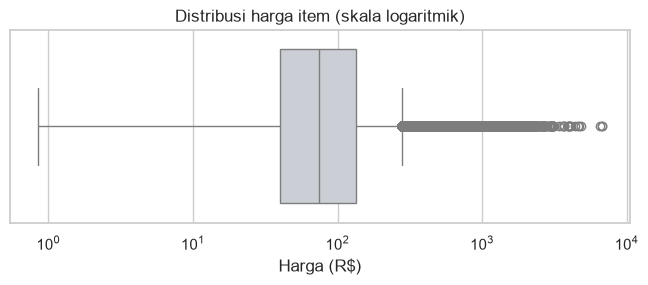

In [98]:
price = order_items_df['price']
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(price.describe())
print(f'\nBatas atas outlier (IQR): {upper:,.2f}')
print(f'Jumlah item di atas batas: {(price > upper).sum():,} ({(price > upper).mean()*100:.1f}%)')

fig, ax = plt.subplots(figsize=(8, 2.5))
sns.boxplot(x=price, ax=ax, color=MUTED)
ax.set_xscale('log')
ax.set_title('Distribusi harga item (skala logaritmik)')
ax.set_xlabel('Harga (R$)')
plt.show()

**Steps to Take:**
- Sekitar 7,5% item memiliki harga di atas batas IQR, tetapi harga tinggi pada marketplace adalah hal wajar (mis. barang elektronik/furnitur), bukan kesalahan input.
- Outlier **tidak dibuang** agar total *revenue* tidak berkurang secara artifisial. Untuk membaca pola, analisis memakai total & rata-rata sekaligus.

**Insight:**
- Masalah kualitas data yang ditemukan: *missing value*, data duplikat (geolocation & review), *invalid value* (berat 0 g, koordinat di luar Brasil), *inaccurate value* (kategori tanpa terjemahan, bulan tidak lengkap), serta *outlier* harga.
- Tidak semua pesanan layak dianalisis: hanya pesanan `delivered` yang merepresentasikan pendapatan nyata dan memiliki data pengiriman yang lengkap.

### Cleaning Data

#### Cleaning orders: hanya pesanan terkirim pada periode Januari 2017 – Agustus 2018

In [99]:
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

orders_clean = orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_delivered_customer_date'].notna()) &
    (orders_df['order_purchase_timestamp'] >= '2017-01-01') &
    (orders_df['order_purchase_timestamp'] < '2018-09-01')
].copy()

print(f'Sebelum: {len(orders_df):,} pesanan  ->  Sesudah: {len(orders_clean):,} pesanan')
print(orders_clean['order_purchase_timestamp'].min(), 's.d.', orders_clean['order_purchase_timestamp'].max())

Sebelum: 99,441 pesanan  ->  Sesudah: 96,203 pesanan
2017-01-05 11:56:06 s.d. 2018-08-29 15:00:37


#### Cleaning products: terjemahan kategori & berat produk

In [100]:
manual_translation = {
    'pc_gamer': 'pc_gamer',
    'portateis_cozinha_e_preparadores_de_alimentos': 'portable_kitchen_food_preparers',
}
category_map = dict(zip(category_df['product_category_name'], category_df['product_category_name_english']))
category_map.update(manual_translation)

products_clean = products_df.copy()
products_clean['product_category'] = (products_clean['product_category_name']
                                      .map(category_map)
                                      .fillna('unknown'))
products_clean['product_weight_g'] = products_clean['product_weight_g'].replace(0, np.nan)

print('Kategori unknown :', (products_clean['product_category'] == 'unknown').sum())
print('Jumlah kategori  :', products_clean['product_category'].nunique())

Kategori unknown : 610
Jumlah kategori  : 74


#### Cleaning order_reviews: satu ulasan terbaru per pesanan

In [101]:
reviews_clean = (order_reviews_df
                 .sort_values('review_answer_timestamp')
                 .drop_duplicates(subset='order_id', keep='last'))

print('Duplikat order_id setelah dibersihkan :', reviews_clean['order_id'].duplicated().sum())
print('Jumlah ulasan unik                    :', len(reviews_clean))

Duplikat order_id setelah dibersihkan : 0
Jumlah ulasan unik                    : 98673


#### Cleaning geolocation: duplikat, koordinat invalid, dan ringkasan per kode pos

In [102]:
geo_clean = geolocation_df.drop_duplicates()
geo_clean = geo_clean[
    geo_clean['geolocation_lat'].between(-33.75, 5.27) &
    geo_clean['geolocation_lng'].between(-73.99, -34.79)
]

geo_zip = (geo_clean
           .groupby('geolocation_zip_code_prefix', as_index=False)
           .agg(customer_lat=('geolocation_lat', 'mean'),
                customer_lng=('geolocation_lng', 'mean')))

print(f'Baris geolocation: {len(geolocation_df):,} -> {len(geo_clean):,} -> {len(geo_zip):,} kode pos unik')

Baris geolocation: 1,000,163 -> 738,299 -> 19,010 kode pos unik


#### Membangun tabel utama (*master data*)
Seluruh tabel yang sudah bersih digabungkan menjadi dua tabel:
1. `orders_master`: **satu baris per pesanan** (dipakai untuk pengiriman, skor ulasan, RFM, dan geospatial).
2. `items_master`: **satu baris per item** (dipakai untuk *revenue* per kategori).

In [103]:
orders_master = (orders_clean
                 .merge(customers_df, on='customer_id', how='left')
                 .merge(reviews_clean[['order_id', 'review_score']], on='order_id', how='left')
                 .merge(geo_zip, left_on='customer_zip_code_prefix',
                        right_on='geolocation_zip_code_prefix', how='left'))

# Lama pengiriman (hari) & selisih terhadap estimasi (hari). Positif = terlambat.
orders_master['delivery_days'] = (orders_master['order_delivered_customer_date']
                                  - orders_master['order_purchase_timestamp']).dt.total_seconds() / 86400
orders_master['delay_days'] = (orders_master['order_delivered_customer_date'].dt.normalize()
                               - orders_master['order_estimated_delivery_date'].dt.normalize()).dt.days
orders_master['is_late'] = orders_master['delay_days'] > 0

orders_master = orders_master[['order_id', 'customer_unique_id', 'customer_state', 'customer_city',
                               'order_purchase_timestamp', 'order_delivered_customer_date',
                               'order_estimated_delivery_date', 'delivery_days', 'delay_days',
                               'is_late', 'review_score', 'customer_lat', 'customer_lng']]

items_master = (order_items_df[['order_id', 'product_id', 'price', 'freight_value']]
                .merge(orders_master, on='order_id', how='inner')
                .merge(products_clean[['product_id', 'product_category']], on='product_id', how='left'))

print('orders_master :', orders_master.shape)
print('items_master  :', items_master.shape)
items_master.head()

orders_master : (96203, 13)
items_master  : (109872, 17)


,order_id,product_id,price,freight_value,customer_unique_id,customer_state,customer_city,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days,is_late,review_score,customer_lat,customer_lng,product_category
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,58.90,13.29,871766c5855e863f6eccc05f988b23cb,RJ,campos dos goytacazes,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,7.614421,-9,False,5.0,-21.763186,-41.310265,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,239.90,19.93,eb28e67c4c0b83846050ddfb8a35d051,SP,santa fe do sul,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,16.216181,-3,False,4.0,-20.222506,-50.898951,pet_shop
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,199.00,17.87,3818d81c6709e39d06b2738a8d3a2474,MG,para de minas,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,7.948437,-14,False,5.0,-19.869998,-44.593059,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,12.99,12.79,af861d436cfc08b2c2ddefd0ba074622,SP,atibaia,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,6.147269,-6,False,4.0,-23.105968,-46.590277,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,199.90,18.14,64b576fb70d441e8f1b2d7d446e483c5,SP,varzea paulista,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,25.114352,-16,False,5.0,-23.243402,-46.827614,garden_tools


In [104]:
# Pengecekan akhir kualitas data
print('Missing value pada items_master:')
print(items_master.isna().sum()[items_master.isna().sum() > 0])
print('\nBaris duplikat orders_master :', orders_master.duplicated(subset='order_id').sum())

Missing value pada items_master:
review_score    823
customer_lat    289
customer_lng    289
dtype: int64

Baris duplikat orders_master : 0


**Insight:**
- Setelah pembersihan, tersisa **96.203 pesanan** (delivered, Jan 2017 – Agustus 2018) dengan **±110 ribu item**.
- *Missing value* yang tersisa hanya pada `review_score` (pesanan tanpa ulasan) dan koordinat (kode pos yang tidak ada di tabel geolocation). Keduanya dibiarkan dan akan otomatis diabaikan pada perhitungan yang membutuhkannya.
- Tiap pesanan kini hanya muncul satu kali di `orders_master`, sehingga rata-rata skor ulasan tidak lagi bias oleh duplikasi.

## Exploratory Data Analysis (EDA)

### Explore ringkasan umum

In [105]:
ringkasan = pd.Series({
    'Total pesanan': orders_master['order_id'].nunique(),
    'Total pelanggan unik': orders_master['customer_unique_id'].nunique(),
    'Total revenue (R$)': items_master['price'].sum(),
    'Total ongkir (R$)': items_master['freight_value'].sum(),
    'Rata-rata nilai item (R$)': items_master['price'].mean(),
    'Rata-rata skor ulasan': orders_master['review_score'].mean(),
    'Rata-rata lama pengiriman (hari)': orders_master['delivery_days'].mean(),
    'Persentase pesanan terlambat (%)': orders_master['is_late'].mean() * 100,
})
ringkasan.round(2).to_frame('nilai')

,nilai
Total pesanan,96203.00
Total pelanggan unik,93096.00
Total revenue (R$),13179777.95
Total ongkir (R$),2191963.14
Rata-rata nilai item (R$),119.96
Rata-rata skor ulasan,4.16
Rata-rata lama pengiriman (hari),12.54
Persentase pesanan terlambat (%),6.79


In [106]:
orders_master[['delivery_days', 'delay_days', 'review_score']].describe().round(2)

,delivery_days,delay_days,review_score
count,96203.00,96203.00,95560.00
mean,12.54,-11.81,4.16
std,9.53,10.09,1.28
min,0.53,-147.00,1.00
25%,6.76,-17.00,4.00
50%,10.21,-12.00,5.00
75%,15.68,-7.00,5.00
max,209.63,188.00,5.00


### Explore revenue per kategori produk (Pertanyaan 1)

In [107]:
category_rev = (items_master.groupby('product_category')
                .agg(revenue=('price', 'sum'),
                     jumlah_item=('order_id', 'count'),
                     rata2_harga=('price', 'mean'))
                .sort_values('revenue', ascending=False))
category_rev['kontribusi_pct'] = category_rev['revenue'] / category_rev['revenue'].sum() * 100
category_rev['kontribusi_kumulatif_pct'] = category_rev['kontribusi_pct'].cumsum()

print('Jumlah kategori:', len(category_rev))
print(f"Kontribusi Top 5 kategori : {category_rev['kontribusi_pct'].head(5).sum():.1f}%")
print(f"Kontribusi Top 10 kategori: {category_rev['kontribusi_pct'].head(10).sum():.1f}%")
print(f"Kontribusi 5 kategori terkecil: {category_rev['kontribusi_pct'].tail(5).sum():.3f}%")
category_rev.head(10).round(2)

Jumlah kategori: 74
Kontribusi Top 5 kategori : 39.9%
Kontribusi Top 10 kategori: 62.5%
Kontribusi 5 kategori terkecil: 0.026%


,revenue,jumlah_item,rata2_harga,kontribusi_pct,kontribusi_kumulatif_pct
product_category,,,,,
health_beauty,1229557.50,9422,130.50,9.33,9.33
watches_gifts,1163187.91,5853,198.73,8.83,18.15
bed_bath_table,1022955.77,10945,93.46,7.76,25.92
sports_leisure,952661.40,8413,113.24,7.23,33.14
computers_accessories,887944.60,7631,116.36,6.74,39.88
furniture_decor,706237.17,8095,87.24,5.36,45.24
housewares,614341.62,6783,90.57,4.66,49.90
cool_stuff,609158.00,3711,164.15,4.62,54.52
auto,577721.09,4131,139.85,4.38,58.91


In [108]:
category_rev.tail(5).round(2)

,revenue,jumlah_item,rata2_harga,kontribusi_pct,kontribusi_kumulatif_pct
product_category,,,,,
flowers,1110.04,33,33.64,0.01,99.98
home_comfort_2,760.27,30,25.34,0.01,99.99
cds_dvds_musicals,730.00,14,52.14,0.01,99.99
fashion_childrens_clothes,519.95,7,74.28,0.00,100.00
security_and_services,283.29,2,141.64,0.00,100.00


**Insight:**
- Lima kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) menyumbang sekitar **40%** dari seluruh *revenue*.
- Terdapat ekor distribusi yang sangat panjang: lima kategori terkecil hanya menyumbang sekitar 0,03% *revenue* (total ±R$ 3,4 ribu dari R$ 13,2 juta).
- `watches_gifts` memiliki rata-rata harga per item jauh lebih tinggi dibanding `bed_bath_table`, artinya kontribusinya didorong oleh nilai transaksi, bukan volume.

### Explore tren pesanan & revenue bulanan (Pertanyaan 2)

In [109]:
items_master['bulan'] = items_master['order_purchase_timestamp'].dt.to_period('M')

monthly = (items_master.groupby('bulan')
           .agg(jumlah_pesanan=('order_id', 'nunique'), revenue=('price', 'sum')))
monthly['mom_revenue_pct'] = monthly['revenue'].pct_change() * 100
monthly['mom_pesanan_pct'] = monthly['jumlah_pesanan'].pct_change() * 100
monthly.round(2)

,jumlah_pesanan,revenue,mom_revenue_pct,mom_pesanan_pct
bulan,,,,
2017-01,750,111798.36,NaN,NaN
2017-02,1653,234223.40,109.51,120.40
2017-03,2546,359198.85,53.36,54.02
2017-04,2303,340669.68,-5.16,-9.54
2017-05,3545,489159.25,43.59,53.93
2017-06,3135,421923.37,-13.75,-11.57
2017-07,3872,481604.52,14.15,23.51
2017-08,4193,554699.70,15.18,8.29
2017-09,4150,607399.67,9.50,-1.03


In [110]:
ytd_2017 = monthly.loc['2017-01':'2017-08', ['jumlah_pesanan', 'revenue']].sum()
ytd_2018 = monthly.loc['2018-01':'2018-08', ['jumlah_pesanan', 'revenue']].sum()
yoy = (ytd_2018 / ytd_2017 - 1) * 100

pd.DataFrame({'Jan-Agu 2017': ytd_2017, 'Jan-Agu 2018': ytd_2018, 'YoY (%)': yoy}).round(2)

,Jan-Agu 2017,Jan-Agu 2018,YoY (%)
jumlah_pesanan,21997.00,52777.00,139.93
revenue,2993277.13,7217172.24,141.11


In [111]:
print('Bulan dengan revenue tertinggi :', monthly['revenue'].idxmax(), f"(R$ {monthly['revenue'].max():,.0f})")
print('Rata-rata MoM revenue 2018     :', round(monthly.loc['2018-02':'2018-08', 'mom_revenue_pct'].mean(), 2), '%')
print('Rata-rata revenue Jan-Agu 2018 :', round(monthly.loc['2018-01':'2018-08', 'revenue'].mean(), 0))

Bulan dengan revenue tertinggi : 2017-11 (R$ 987,648)
Rata-rata MoM revenue 2018     : -1.02 %
Rata-rata revenue Jan-Agu 2018 : 902147.0


**Insight:**
- *Revenue* Januari–Agustus 2018 tumbuh sekitar **+141% (YoY)** dibanding periode yang sama pada 2017, dan jumlah pesanan tumbuh sekitar **+140%**.
- Puncak *revenue* terjadi pada **November 2017** (±R$ 988 ribu, lonjakan +52% dari Oktober), kemungkinan besar dipicu momen belanja akhir tahun seperti *Black Friday*, lalu turun 26% pada Desember.
- Sepanjang 2018, pertumbuhan melambat dan cenderung mendatar: rata-rata MoM *revenue* Februari–Agustus 2018 justru sekitar -1,0%, dengan fluktuasi di kisaran R$ 0,83–0,98 juta per bulan.

### Explore keterlambatan pengiriman vs skor ulasan (Pertanyaan 3)

In [112]:
# Binning keterlambatan pengiriman terhadap estimasi (delay_days: negatif = lebih cepat)
bins = [-np.inf, -8, 0, 3, 7, 14, np.inf]
labels = ['Lebih cepat > 7 hari', 'Tepat waktu / lebih cepat <= 7 hari',
          'Telat 1-3 hari', 'Telat 4-7 hari', 'Telat 8-14 hari', 'Telat > 14 hari']
orders_master['kelompok_pengiriman'] = pd.cut(orders_master['delay_days'], bins=bins, labels=labels)

delay_review = (orders_master.dropna(subset=['review_score'])
                .groupby('kelompok_pengiriman', observed=True)
                .agg(jumlah_pesanan=('order_id', 'count'), rata2_review=('review_score', 'mean')))
delay_review['persen_pesanan'] = delay_review['jumlah_pesanan'] / delay_review['jumlah_pesanan'].sum() * 100
delay_review.round(2)

,jumlah_pesanan,rata2_review,persen_pesanan
kelompok_pengiriman,,,
Lebih cepat > 7 hari,70673,4.32,73.96
Tepat waktu / lebih cepat <= 7 hari,18509,4.19,19.37
Telat 1-3 hari,1851,3.29,1.94
Telat 4-7 hari,1748,2.10,1.83
Telat 8-14 hari,1446,1.67,1.51
Telat > 14 hari,1333,1.72,1.39


In [113]:
review_df = orders_master.dropna(subset=['review_score'])
late_vs_ontime = (review_df.groupby('is_late')
                  .agg(jumlah_pesanan=('order_id', 'count'), rata2_review=('review_score', 'mean')))
late_vs_ontime.index = ['Tepat waktu / lebih cepat', 'Terlambat']
print(late_vs_ontime.round(2))
print('\nSelisih skor :', round(late_vs_ontime['rata2_review'].iloc[0] - late_vs_ontime['rata2_review'].iloc[1], 2), 'poin')
print('Persentase pesanan terlambat:', round(orders_master['is_late'].mean() * 100, 2), '%')

                           jumlah_pesanan  rata2_review
Tepat waktu / lebih cepat           89182          4.29
Terlambat                            6378          2.27

Selisih skor : 2.02 poin
Persentase pesanan terlambat: 6.79 %


In [114]:
state_perf = (review_df.groupby('customer_state')
              .agg(jumlah_pesanan=('order_id', 'count'),
                   rata2_review=('review_score', 'mean'),
                   persen_terlambat=('is_late', lambda s: s.mean() * 100),
                   rata2_pengiriman_hari=('delivery_days', 'mean')))

# State dengan sampel kecil (< 100 pesanan) dikeluarkan agar rata-rata tidak bias
state_perf_valid = state_perf[state_perf['jumlah_pesanan'] >= 100].sort_values('persen_terlambat', ascending=False)

print('State dikeluarkan karena < 100 pesanan:', list(state_perf[state_perf['jumlah_pesanan'] < 100].index))
print('Korelasi persen terlambat vs rata-rata review:',
      round(state_perf_valid['persen_terlambat'].corr(state_perf_valid['rata2_review']), 3))
state_perf_valid.head(8).round(2)

State dikeluarkan karena < 100 pesanan: ['AC', 'AP', 'RR']
Korelasi persen terlambat vs rata-rata review: -0.903


,jumlah_pesanan,rata2_review,persen_terlambat,rata2_pengiriman_hari
customer_state,,,,
AL,393,3.85,20.87,24.44
MA,709,3.83,17.21,21.46
SE,331,3.90,15.11,21.36
PI,470,3.99,13.83,19.48
CE,1267,3.94,13.73,21.18
RJ,12172,3.97,11.96,15.23
BA,3226,3.93,11.90,19.24
PA,929,3.91,10.76,23.62


**Insight:**
- Pesanan yang terlambat memiliki rata-rata skor ulasan **±2,27**, sedangkan pesanan tepat waktu **±4,29**: selisih sekitar **2 poin** dari skala 5.
- Semakin lama keterlambatan, semakin rendah skornya: dari ±3,29 (telat 1–3 hari) menjadi ±1,7 (telat lebih dari 1 minggu). Artinya pelanggan relatif masih toleran pada keterlambatan sangat singkat.
- Hanya ±6,8% pesanan yang terlambat, tetapi dampaknya terhadap kepuasan sangat besar. Pesanan terlambat menjadi sumber utama ulasan buruk.
- Secara geografis, **AL (±21%), MA (±17%), SE (±15%), PI, dan CE** memiliki persentase keterlambatan tertinggi, dan skor ulasan di state-state tersebut termasuk yang terendah. Antar-state, persen keterlambatan dan skor ulasan berkorelasi negatif sangat kuat (r ≈ -0,90).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang menjadi 10 kontributor revenue terbesar dan 5 terkecil (Jan 2017 – Agu 2018)?

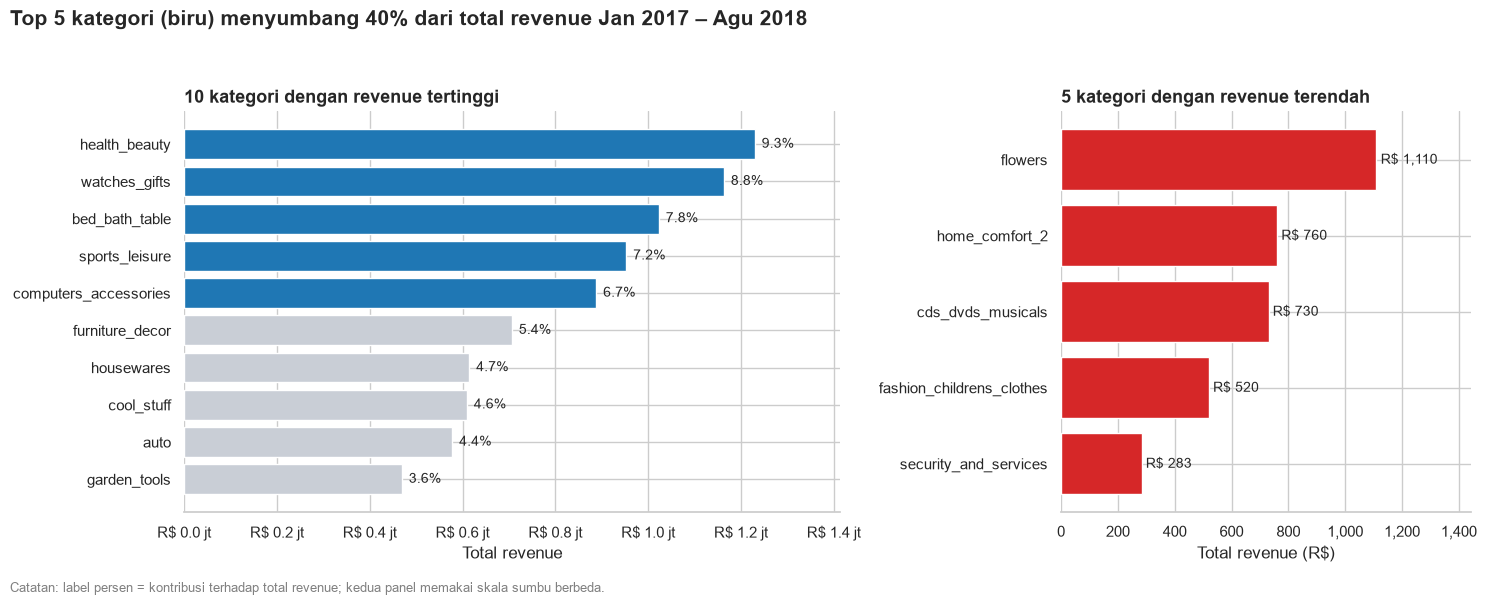

In [115]:
def rupiah_juta(x, pos=None):
    return f'R$ {x/1e6:.1f} jt'

top10 = category_rev.head(10).sort_values('revenue')
bottom5 = category_rev.tail(5).sort_values('revenue')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.6, 1]})

# --- Top 10 (sorot Top 5)
colors_top = [HIGHLIGHT if c in category_rev.head(5).index else MUTED for c in top10.index]
axes[0].barh(top10.index, top10['revenue'], color=colors_top)
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(rupiah_juta))
axes[0].set_title('10 kategori dengan revenue tertinggi', loc='left', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total revenue')
axes[0].set_ylabel('')
for i, (v, p) in enumerate(zip(top10['revenue'], top10['kontribusi_pct'])):
    axes[0].text(v + 15000, i, f'{p:.1f}%', va='center', fontsize=10)
axes[0].set_xlim(0, top10['revenue'].max() * 1.15)

# --- Bottom 5 (skala sendiri agar terbaca)
axes[1].barh(bottom5.index, bottom5['revenue'], color=WARN)
axes[1].set_title('5 kategori dengan revenue terendah', loc='left', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Total revenue (R$)')
axes[1].set_ylabel('')
axes[1].xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
for i, v in enumerate(bottom5['revenue']):
    axes[1].text(v + 15, i, f'R$ {v:,.0f}', va='center', fontsize=10)
axes[1].set_xlim(0, bottom5['revenue'].max() * 1.3)

top5_share = category_rev['kontribusi_pct'].head(5).sum()
fig.suptitle(f'Top 5 kategori (biru) menyumbang {top5_share:.0f}% dari total revenue Jan 2017 – Agu 2018',
             fontsize=15, fontweight='bold', x=0.01, ha='left')
fig.text(0.01, 0.01, 'Catatan: label persen = kontribusi terhadap total revenue; kedua panel memakai skala sumbu berbeda.',
         fontsize=9, color='gray')
sns.despine(left=True)
plt.tight_layout(rect=[0, 0.03, 1, 0.94])
plt.show()

### Pertanyaan 2: Bagaimana tren jumlah pesanan dan revenue bulanan serta pertumbuhan YoY Jan–Agu 2018 vs 2017?

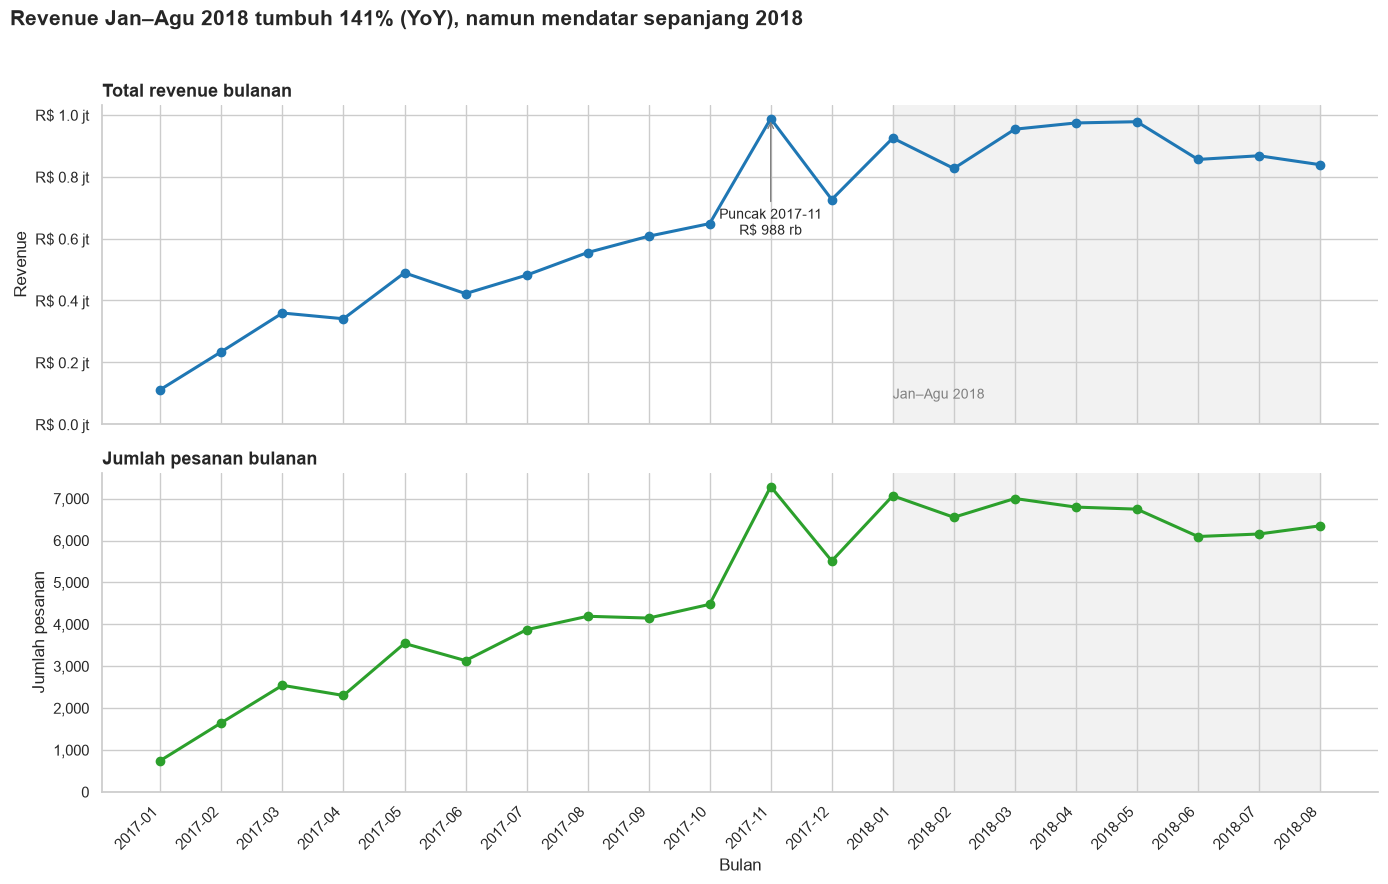

In [116]:
m = monthly.copy()
m.index = m.index.astype(str)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Revenue
axes[0].plot(m.index, m['revenue'], marker='o', color=HIGHLIGHT, linewidth=2.2)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(rupiah_juta))
axes[0].set_title('Total revenue bulanan', loc='left', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Revenue')
peak = m['revenue'].idxmax()
axes[0].annotate(f'Puncak {peak}\nR$ {m.loc[peak, "revenue"]/1e3:,.0f} rb',
                 xy=(peak, m.loc[peak, 'revenue']), xytext=(peak, m['revenue'].max() * 0.62),
                 ha='center', arrowprops=dict(arrowstyle='->', color='gray'), fontsize=10)

# Pesanan
axes[1].plot(m.index, m['jumlah_pesanan'], marker='o', color='#2ca02c', linewidth=2.2)
axes[1].set_title('Jumlah pesanan bulanan', loc='left', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Jumlah pesanan')
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
axes[1].set_xlabel('Bulan')
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')

for ax in axes:
    ax.axvspan('2018-01', '2018-08', color='#f2f2f2', zorder=0)
    ax.set_ylim(bottom=0)
axes[0].text('2018-01', axes[0].get_ylim()[1] * 0.08, 'Jan–Agu 2018', fontsize=10, color='gray')

fig.suptitle(f'Revenue Jan–Agu 2018 tumbuh {yoy["revenue"]:.0f}% (YoY), namun mendatar sepanjang 2018',
             fontsize=15, fontweight='bold', x=0.01, ha='left')
sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

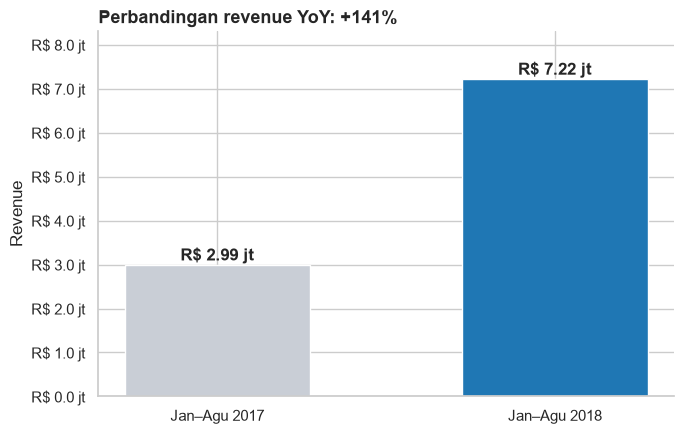

In [117]:
fig, ax = plt.subplots(figsize=(7, 4.5))
vals = [ytd_2017['revenue'], ytd_2018['revenue']]
bars = ax.bar(['Jan–Agu 2017', 'Jan–Agu 2018'], vals, color=[MUTED, HIGHLIGHT], width=0.55)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(rupiah_juta))
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 1e5, f'R$ {v/1e6:.2f} jt', ha='center', fontweight='bold')
ax.set_title(f'Perbandingan revenue YoY: +{yoy["revenue"]:.0f}%', loc='left', fontsize=13, fontweight='bold')
ax.set_ylabel('Revenue')
ax.set_ylim(0, max(vals) * 1.15)
sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 3: Seberapa besar dampak keterlambatan pengiriman terhadap skor ulasan, dan state mana yang paling bermasalah?

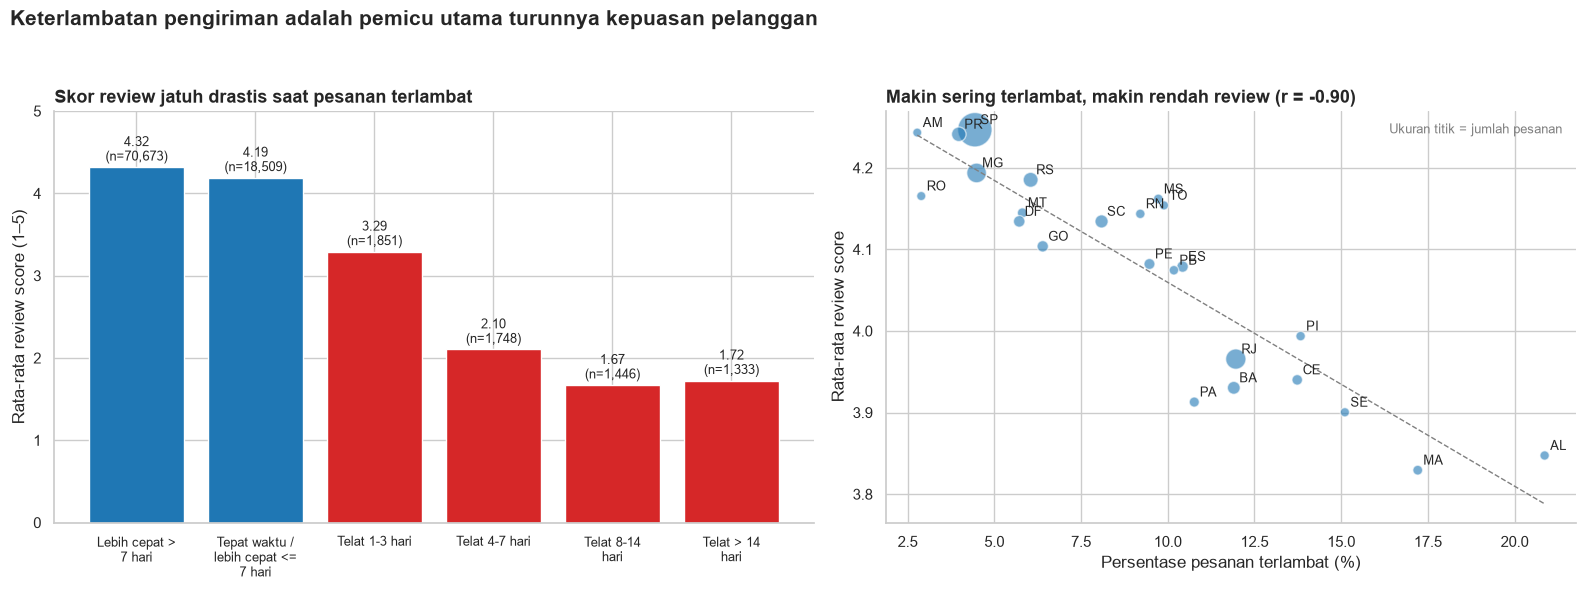

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.1, 1]})

# --- (a) Skor review per kelompok keterlambatan
dr = delay_review.reset_index()
colors = [HIGHLIGHT if 'Telat' not in k else WARN for k in dr['kelompok_pengiriman']]
axes[0].bar(range(len(dr)), dr['rata2_review'], color=colors)
axes[0].set_xticks(range(len(dr)))
axes[0].set_xticklabels([textwrap.fill(l, 14) for l in dr['kelompok_pengiriman'].astype(str)], fontsize=9)
axes[0].set_ylim(0, 5)
axes[0].set_ylabel('Rata-rata review score (1–5)')
axes[0].set_title('Skor review jatuh drastis saat pesanan terlambat', loc='left', fontsize=13, fontweight='bold')
for i, (s, n) in enumerate(zip(dr['rata2_review'], dr['jumlah_pesanan'])):
    axes[0].text(i, s + 0.08, f'{s:.2f}\n(n={n:,})', ha='center', fontsize=9)

# --- (b) Persen terlambat vs skor review per state
sp = state_perf_valid
axes[1].scatter(sp['persen_terlambat'], sp['rata2_review'], s=40 + sp['jumlah_pesanan'] / 70,
                color=HIGHLIGHT, alpha=0.6, edgecolor='white')
for st, row in sp.iterrows():
    axes[1].annotate(st, (row['persen_terlambat'], row['rata2_review']), fontsize=9,
                     xytext=(4, 4), textcoords='offset points')
slope, intercept = np.polyfit(sp['persen_terlambat'], sp['rata2_review'], 1)
xs = np.linspace(sp['persen_terlambat'].min(), sp['persen_terlambat'].max(), 50)
axes[1].plot(xs, slope * xs + intercept, color='gray', linestyle='--', linewidth=1)
corr = sp['persen_terlambat'].corr(sp['rata2_review'])
axes[1].set_xlabel('Persentase pesanan terlambat (%)')
axes[1].set_ylabel('Rata-rata review score')
axes[1].set_title(f'Makin sering terlambat, makin rendah review (r = {corr:.2f})',
                  loc='left', fontsize=13, fontweight='bold')
axes[1].text(0.98, 0.97, 'Ukuran titik = jumlah pesanan', transform=axes[1].transAxes,
             ha='right', va='top', fontsize=9, color='gray')

fig.suptitle('Keterlambatan pengiriman adalah pemicu utama turunnya kepuasan pelanggan',
             fontsize=15, fontweight='bold', x=0.01, ha='left')
sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

**Insight:**
- **Pertanyaan 1:** Revenue sangat terkonsentrasi pada beberapa kategori. Top 5 menyumbang ±40% total, dengan `health_beauty` sebagai yang terbesar, sedangkan kategori seperti `security_and_services` dan `fashion_childrens_clothes` nyaris tidak berkontribusi.
- **Pertanyaan 2:** Pertumbuhan YoY sangat besar (±+141%), tetapi sepanjang 2018 grafik cenderung mendatar sehingga momentum pertumbuhan melemah. Lonjakan November 2017 menunjukkan bahwa momen promosi sangat efektif mendongkrak penjualan.
- **Pertanyaan 3:** Keterlambatan menurunkan skor ulasan sekitar 2 poin, dan state di wilayah utara/timur laut (mis. MA, AL, SE) paling terdampak.

## Analisis Lanjutan (Opsional)

Tiga teknik analisis lanjutan (tanpa algoritma *machine learning*) digunakan untuk memperdalam jawaban atas pertanyaan bisnis:

1. **RFM Analysis + Manual Grouping** — mengelompokkan pelanggan berdasarkan *Recency* (hari sejak pembelian terakhir), *Frequency* (jumlah pesanan), dan *Monetary* (total belanja). Tujuannya agar tim *marketing* tahu segmen mana yang harus diprioritaskan (terkait Pertanyaan 2: bagaimana mendorong pertumbuhan yang mulai mendatar).
2. **Geospatial Analysis** — memetakan sebaran pelanggan dan kualitas layanan berdasarkan lokasi geografis untuk melihat wilayah yang bermasalah (terkait Pertanyaan 3).
3. **Binning** — membagi keterlambatan pengiriman ke dalam interval (sudah diterapkan pada Pertanyaan 3).

### RFM Analysis

In [119]:
# Titik acuan = sehari setelah transaksi terakhir pada periode analisis
snapshot_date = orders_master['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

order_value = items_master.groupby('order_id')['price'].sum().rename('order_value')
rfm_base = orders_master.merge(order_value, on='order_id', how='left')

rfm_df = (rfm_base.groupby('customer_unique_id')
          .agg(last_purchase=('order_purchase_timestamp', 'max'),
               frequency=('order_id', 'nunique'),
               monetary=('order_value', 'sum'))
          .reset_index())
rfm_df['recency'] = (snapshot_date - rfm_df['last_purchase']).dt.days
rfm_df = rfm_df.drop(columns='last_purchase')

print('Jumlah pelanggan unik:', len(rfm_df))
rfm_df[['recency', 'frequency', 'monetary']].describe().round(2)

Jumlah pelanggan unik: 93096


,recency,frequency,monetary
count,93096.00,93096.00,93096.00
mean,236.71,1.03,141.57
std,150.94,0.21,215.77
min,1.00,1.00,0.85
25%,114.00,1.00,47.65
50%,218.00,1.00,89.70
75%,345.00,1.00,154.16
max,602.00,15.00,13440.00


In [120]:
freq_dist = rfm_df['frequency'].value_counts().sort_index()
print((freq_dist / len(rfm_df) * 100).round(2).rename('persen pelanggan').to_frame())

           persen pelanggan
frequency                  
1                     97.00
2                      2.75
3                      0.19
4                      0.03
5                      0.01
6                      0.01
7                      0.00
9                      0.00
15                     0.00


Mayoritas pelanggan hanya membeli **satu kali**, sehingga *Frequency* tidak bisa dibagi dengan kuartil biasa. Karena itu digunakan **manual grouping** berdasarkan aturan bisnis:

- **Frequency:** 1 pesanan, 2 pesanan, atau ≥ 3 pesanan.
- **Recency & Monetary:** skor 1–4 berdasarkan kuartil (skor 4 = paling baru / paling besar belanjanya).

Segmen pelanggan:

| Segmen | Aturan |
|---|---|
| **Repeat Customers** | Frequency ≥ 2 |
| **Big Spender (Aktif)** | Beli 1×, Recency skor ≥ 3, Monetary skor 4 |
| **New / Recent Customers** | Beli 1×, Recency skor ≥ 3, Monetary skor 1–3 |
| **At Risk Big Spender** | Beli 1×, Recency skor ≤ 2, Monetary skor ≥ 3 |
| **Lost / Dormant** | Beli 1×, Recency skor ≤ 2, Monetary skor ≤ 2 |

In [121]:
rfm_df['r_score'] = pd.qcut(rfm_df['recency'].rank(method='first', ascending=False), 4, labels=[1, 2, 3, 4]).astype(int)
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)


def segment(row):
    if row['frequency'] >= 2:
        return 'Repeat Customers'
    if row['r_score'] >= 3:
        return 'Big Spender (Aktif)' if row['m_score'] == 4 else 'New / Recent Customers'
    return 'At Risk Big Spender' if row['m_score'] >= 3 else 'Lost / Dormant'


rfm_df['segment'] = rfm_df.apply(segment, axis=1)

seg_summary = (rfm_df.groupby('segment')
               .agg(jumlah_pelanggan=('customer_unique_id', 'count'),
                    avg_recency=('recency', 'mean'),
                    avg_frequency=('frequency', 'mean'),
                    avg_monetary=('monetary', 'mean'),
                    total_monetary=('monetary', 'sum'))
               .sort_values('total_monetary', ascending=False))
seg_summary['persen_pelanggan'] = seg_summary['jumlah_pelanggan'] / seg_summary['jumlah_pelanggan'].sum() * 100
seg_summary['persen_revenue'] = seg_summary['total_monetary'] / seg_summary['total_monetary'].sum() * 100
seg_summary.round(2)

,jumlah_pelanggan,avg_recency,avg_frequency,avg_monetary,total_monetary,persen_pelanggan,persen_revenue
segment,,,,,,,
At Risk Big Spender,21970,362.52,1.00,233.61,5132518.21,23.60,38.94
Big Spender (Aktif),10695,111.47,1.00,353.35,3779060.32,11.49,28.67
New / Recent Customers,34320,111.46,1.00,71.14,2441614.95,36.87,18.53
Lost / Dormant,23322,361.99,1.00,47.22,1101229.43,25.05,8.36
Repeat Customers,2789,219.60,2.11,260.08,725355.04,3.00,5.50


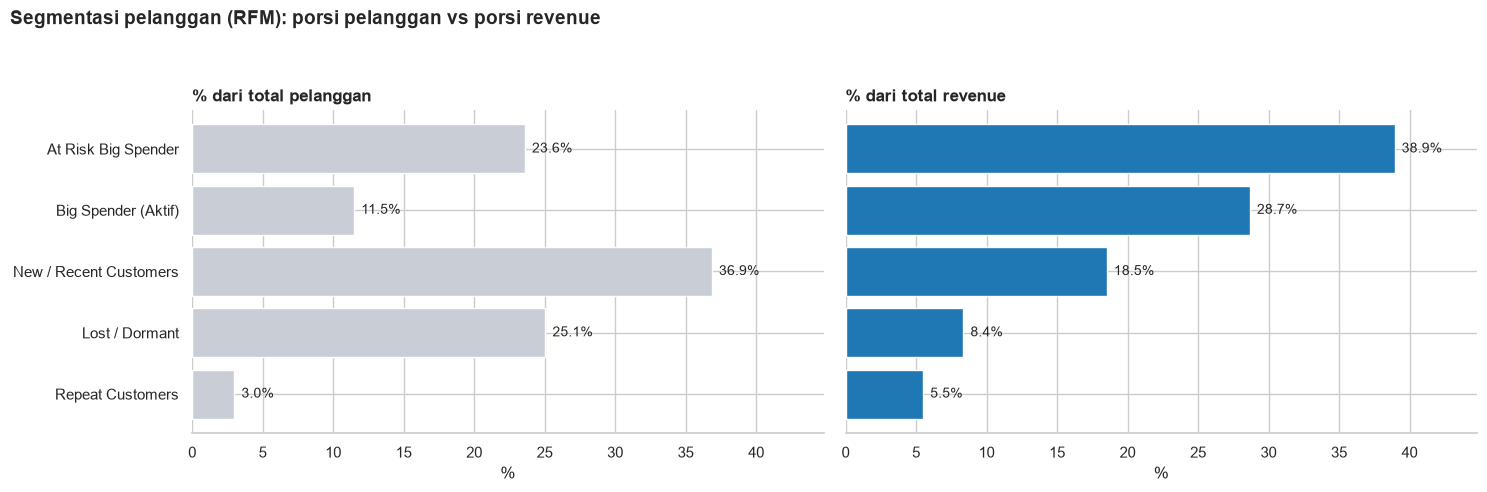

In [122]:
seg_order = seg_summary.sort_values('persen_revenue').index
seg_plot = seg_summary.loc[seg_order]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
axes[0].barh(seg_plot.index, seg_plot['persen_pelanggan'], color=MUTED)
axes[0].set_title('% dari total pelanggan', loc='left', fontsize=12, fontweight='bold')
axes[0].set_xlabel('%')
axes[1].barh(seg_plot.index, seg_plot['persen_revenue'], color=HIGHLIGHT)
axes[1].set_title('% dari total revenue', loc='left', fontsize=12, fontweight='bold')
axes[1].set_xlabel('%')
for ax, col in zip(axes, ['persen_pelanggan', 'persen_revenue']):
    for i, v in enumerate(seg_plot[col]):
        ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=10)
    ax.set_xlim(0, seg_plot[[ 'persen_pelanggan', 'persen_revenue']].max().max() * 1.15)
fig.suptitle('Segmentasi pelanggan (RFM): porsi pelanggan vs porsi revenue', fontsize=14,
             fontweight='bold', x=0.01, ha='left')
sns.despine(left=True)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Insight:**
- **97% pelanggan hanya membeli satu kali.** Pelanggan *repeat* hanya 3,0% (±2,8 ribu orang) dan menyumbang 5,5% *revenue*, sehingga pertumbuhan penjualan hampir sepenuhnya bergantung pada akuisisi pelanggan baru. Ini selaras dengan pertumbuhan 2018 yang mendatar (Pertanyaan 2).
- **At Risk Big Spender** adalah segmen paling bernilai untuk dikejar: 23,6% pelanggan (±22 ribu) menyumbang **38,9% *revenue*** (rata-rata belanja ±R$ 234), tetapi terakhir membeli rata-rata ±363 hari lalu.
- **Big Spender (Aktif)** hanya 11,5% pelanggan namun menghasilkan **28,7% *revenue*** (rata-rata belanja ±R$ 353) dan baru bertransaksi ±111 hari lalu. Segmen ini perlu dijaga agar tidak berpindah menjadi *at risk*.
- **Lost / Dormant** berisi 25,1% pelanggan tetapi hanya 8,4% *revenue* (rata-rata belanja ±R$ 47), sehingga prioritas *win-back*-nya rendah.

### Geospatial Analysis
Koordinat pelanggan diambil dari rata-rata koordinat per kode pos. Peta dibuat dengan *scatter plot* longitude–latitude (tanpa *shapefile*), sehingga bentuk wilayah Brasil terbentuk dari sebaran titik pelanggan itu sendiri.

In [123]:
geo_points = orders_master.dropna(subset=['customer_lat', 'customer_lng'])

state_geo = (geo_points.groupby('customer_state')
             .agg(jumlah_pesanan=('order_id', 'count'),
                  lat=('customer_lat', 'mean'),
                  lng=('customer_lng', 'mean'))
             .join(state_perf[['rata2_review', 'persen_terlambat']]))

state_rev = items_master.groupby('customer_state')['price'].sum().rename('revenue')
state_geo = state_geo.join(state_rev)
state_geo['persen_pesanan'] = state_geo['jumlah_pesanan'] / state_geo['jumlah_pesanan'].sum() * 100
state_geo['jumlah_terlambat'] = orders_master.groupby('customer_state')['is_late'].sum()

print('Top 5 state berdasarkan jumlah pesanan:')
print(state_geo.sort_values('jumlah_pesanan', ascending=False).head(5)[['jumlah_pesanan', 'persen_pesanan', 'revenue']].round(2))
print(f"\nSP + RJ + MG = {state_geo.loc[['SP', 'RJ', 'MG'], 'persen_pesanan'].sum():.1f}% dari seluruh pesanan")
print('\nState dengan pesanan terlambat terbanyak (jumlah absolut):')
print(state_geo.sort_values('jumlah_terlambat', ascending=False).head(5)[['jumlah_pesanan', 'jumlah_terlambat', 'persen_terlambat']].round(1))
print(f"SP + RJ + MG = {state_geo.loc[['SP', 'RJ', 'MG'], 'jumlah_terlambat'].sum() / state_geo['jumlah_terlambat'].sum() * 100:.1f}% dari seluruh pesanan terlambat")

Top 5 state berdasarkan jumlah pesanan:
                jumlah_pesanan  persen_pesanan     revenue
customer_state                                            
SP                       40385           42.09  5054516.95
RJ                       12297           12.82  1751433.85
MG                       11310           11.79  1548206.88
RS                        5323            5.55   726194.92
PR                        4891            5.10   664048.00

SP + RJ + MG = 66.7% dari seluruh pesanan

State dengan pesanan terlambat terbanyak (jumlah absolut):
                jumlah_pesanan  jumlah_terlambat  persen_terlambat
customer_state                                                    
SP                       40385              1817               4.4
RJ                       12297              1495              12.0
MG                       11310               519               4.5
BA                        3245               396              11.9
RS                        5323            

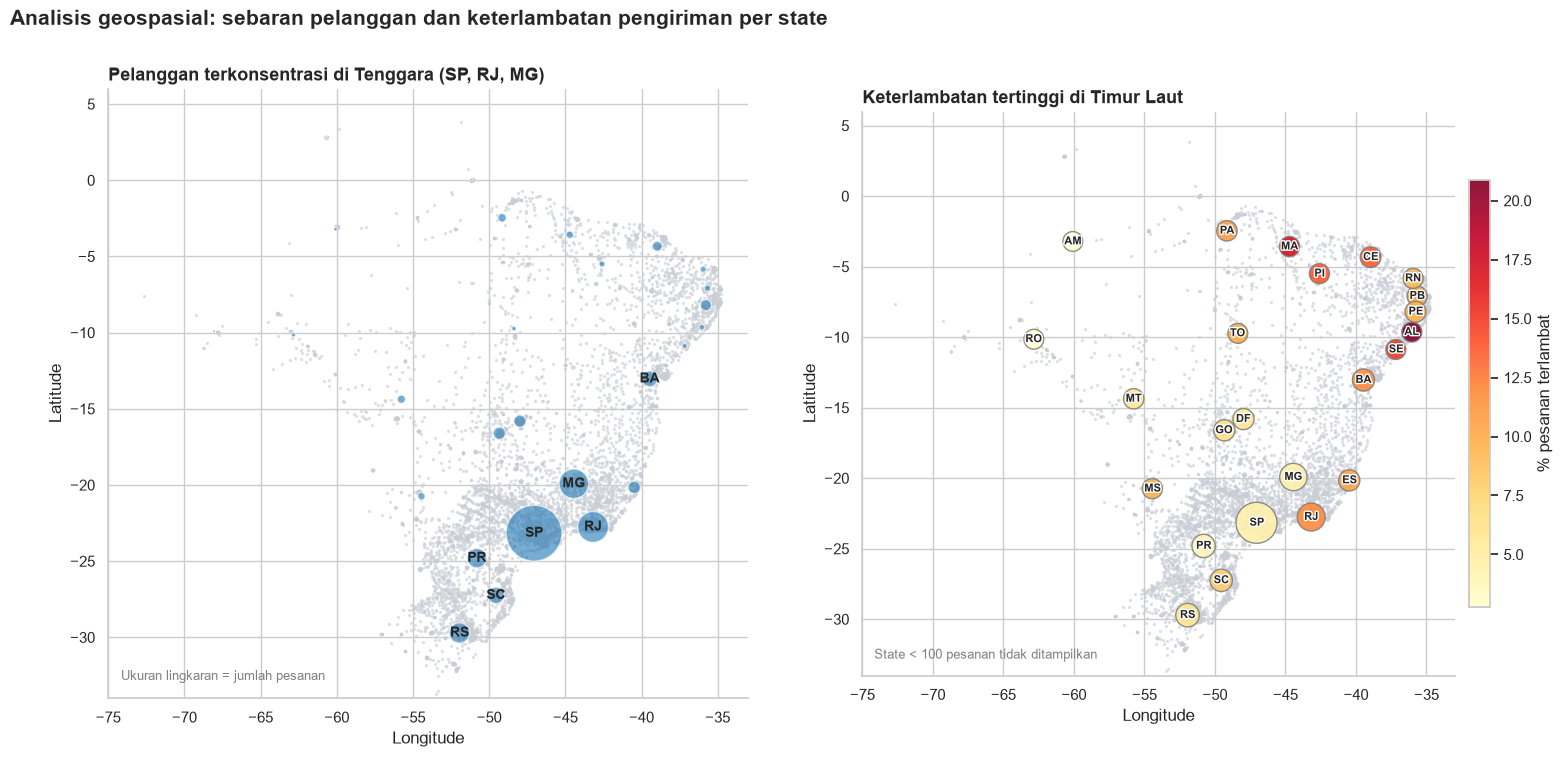

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))

unique_zip = geo_points.drop_duplicates(subset=['customer_lat', 'customer_lng'])

# --- Peta 1: Sebaran jumlah pesanan
for ax in axes:
    ax.scatter(unique_zip['customer_lng'], unique_zip['customer_lat'], s=2, color=MUTED, alpha=0.5)
    ax.set_xlim(-75, -33)
    ax.set_ylim(-34, 6)
    ax.set_aspect('equal')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

sc1 = axes[0].scatter(state_geo['lng'], state_geo['lat'], s=state_geo['jumlah_pesanan'] / 25,
                      color=HIGHLIGHT, alpha=0.6, edgecolor='white')
for st, row in state_geo.iterrows():
    if row['jumlah_pesanan'] > 3000:
        axes[0].annotate(st, (row['lng'], row['lat']), ha='center', va='center', fontsize=10, fontweight='bold')
axes[0].set_title('Pelanggan terkonsentrasi di Tenggara (SP, RJ, MG)', loc='left', fontsize=13, fontweight='bold')
axes[0].text(0.02, 0.03, 'Ukuran lingkaran = jumlah pesanan', transform=axes[0].transAxes, fontsize=9, color='gray')

# --- Peta 2: Persen keterlambatan
geo_valid = state_geo[state_geo['jumlah_pesanan'] >= 100]   # state < 100 pesanan dikeluarkan (sampel terlalu kecil)
sc2 = axes[1].scatter(geo_valid['lng'], geo_valid['lat'], s=200 + geo_valid['jumlah_pesanan'] / 60,
                      c=geo_valid['persen_terlambat'], cmap='YlOrRd', edgecolor='gray', alpha=0.9)
for st, row in geo_valid.iterrows():
    axes[1].annotate(st, (row['lng'], row['lat']), ha='center', va='center', fontsize=8, fontweight='bold',
                     path_effects=[pe.withStroke(linewidth=2, foreground='white')])
cbar = fig.colorbar(sc2, ax=axes[1], shrink=0.7, pad=0.02)
cbar.set_label('% pesanan terlambat')
axes[1].set_title('Keterlambatan tertinggi di Timur Laut', loc='left', fontsize=13, fontweight='bold')
axes[1].text(0.02, 0.03, 'State < 100 pesanan tidak ditampilkan', transform=axes[1].transAxes, fontsize=9, color='gray')

fig.suptitle('Analisis geospasial: sebaran pelanggan dan keterlambatan pengiriman per state',
             fontsize=15, fontweight='bold', x=0.01, ha='left')
sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Insight:**
- Pelanggan sangat terkonsentrasi di Tenggara: **SP 42,1%, RJ 12,8%, MG 11,8%** (total 66,7% pesanan).
- Keterlambatan paling tinggi berada di wilayah **Timur Laut** (AL ±21%, MA ±17%, SE ±15%, PI, CE), dengan rata-rata lama pengiriman 19–24 hari. Wilayah ini berada jauh dari pusat konsentrasi pesanan di Tenggara.
- **RJ** layak mendapat perhatian khusus: tingkat keterlambatannya ±12% (jauh di atas SP/MG ±4–5%) pada volume pesanan yang besar, sehingga jumlah pesanan terlambatnya terbesar kedua setelah SP.
- SP, RJ, dan MG bersama-sama menyumbang ±59% dari seluruh pesanan terlambat karena volumenya besar, sehingga perbaikan logistik di tiga state ini berdampak besar pada angka keseluruhan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Lima kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) menyumbang **39,9%** dari total *revenue* R$ 13,2 juta, dengan `health_beauty` sebagai yang terbesar (R$ 1,23 juta; 9,3%). Sepuluh kategori teratas menyumbang 62,5%, sedangkan lima kategori terendah (mis. `flowers`, `security_and_services`) hanya berkontribusi ±R$ 3,4 ribu (0,03%).
- **Conclusion pertanyaan 2:** *Revenue* Januari–Agustus 2018 mencapai R$ 7,22 juta, tumbuh **+141% (YoY)** dari R$ 2,99 juta pada periode yang sama 2017 (jumlah pesanan +140%). Puncak terjadi pada November 2017 (R$ 988 ribu). Namun sepanjang 2018 *revenue* mendatar di kisaran R$ 0,83–0,98 juta per bulan (rata-rata MoM Feb–Agu ≈ -1,0%), artinya pertumbuhan mulai jenuh.
- **Conclusion pertanyaan 3:** Pesanan terlambat memiliki skor ulasan rata-rata **2,27** vs **4,29** pada pesanan tepat waktu (selisih ±2,0 poin), padahal hanya 6,8% pesanan yang terlambat. Skor jatuh tajam mulai keterlambatan 4 hari (±2,1) dan menyentuh ±1,7 bila telat lebih dari seminggu. Keterlambatan terparah ada di **AL (±21%), MA (±17%), SE (±15%), PI, dan CE**, dan RJ (±12%) bermasalah pada volume besar; korelasi persen keterlambatan vs skor ulasan antar-state sangat kuat (r ≈ -0,90).

**Rekomendasi Action Item:**
1. **Perbaiki logistik di state prioritas.** Terapkan target ketepatan pengiriman dan pantau mingguan untuk Timur Laut (AL, MA, SE, PI, CE, BA) serta RJ. Evaluasi mitra kurir di rute tersebut, dan sesuaikan estimasi tiba agar lebih realistis di wilayah dengan lama pengiriman 19–24 hari.
2. **Komunikasi proaktif untuk pesanan yang berisiko telat.** Skor ulasan jatuh tajam setelah keterlambatan 3 hari, jadi kirim notifikasi status/permintaan maaf dan kompensasi (voucher/ongkir gratis) sebelum pelanggan memberi ulasan buruk.
3. **Kampanye *win-back* untuk segmen At Risk Big Spender** (±22 ribu pelanggan, ±39% *revenue*) dan program loyalitas/*cross-sell* untuk Big Spender (Aktif). Segmen Lost/Dormant tidak diprioritaskan karena kontribusinya kecil.
4. **Fokuskan stok dan promosi pada Top 5 kategori** (39,9% *revenue*), terutama `health_beauty` dan `watches_gifts` yang bernilai tinggi. Evaluasi kategori dengan kontribusi nyaris nol (mis. digabung ke kategori lain atau di-*delist*).
5. **Jadwalkan kampanye musiman** (akhir tahun/*Black Friday*) dan promo di bulan-bulan lesu seperti Juni–Agustus untuk menembus pertumbuhan yang mendatar sepanjang 2018.

### Menyimpan data untuk dashboard
Tabel `items_master` yang sudah bersih disimpan sebagai `dashboard/main_data.csv` untuk dipakai oleh dashboard Streamlit.

In [125]:
main_data = items_master[['order_id', 'customer_unique_id', 'customer_state', 'customer_city',
                          'order_purchase_timestamp', 'order_delivered_customer_date',
                          'order_estimated_delivery_date', 'delivery_days', 'delay_days',
                          'is_late', 'review_score', 'customer_lat', 'customer_lng',
                          'product_category', 'price', 'freight_value']].copy()
main_data['customer_lat'] = main_data['customer_lat'].round(4)
main_data['customer_lng'] = main_data['customer_lng'].round(4)
main_data['delivery_days'] = main_data['delivery_days'].round(2)

main_data.to_csv('dashboard/main_data.csv', index=False)
print(main_data.shape)

(109872, 16)
